# 02. Data Cleaning & Credit Risk Feature Engineering

### Project: Fintech Credit Risk & Loan Portfolio Vintage Analysis

**Objective:** Standardize raw loan attributes, handle outliers, construct delinquency aging buckets (30/60/90+ DPD), tag regulatory Non-Performing Assets (NPAs), engineer borrower risk tiers (Low, Moderate, High), and prepare sanitized facts for downstream modeling across 22 sequential steps.


## 1. Environment Configuration & Library Ingestion
Initialize processing environment.


In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
print('Preprocessing pipeline initialized.')


Preprocessing pipeline initialized.


## 2. Ingestion of Raw Transaction Dataset
Load raw portfolio data into analytical working memory.


In [2]:
df = pd.read_csv('data/loan_portfolio_raw.csv')
print(f'Ingested {len(df):,} records for feature engineering.')


Ingested 105,000 records for feature engineering.


## 3. Timestamp Parsing & Origination Calendar Attributes
Convert issue date into standardized datetime objects and extract year/month.


In [3]:
df['IssueDate'] = pd.to_datetime(df['IssueDate'])
df['OriginationYear'] = df['IssueDate'].dt.year
df['OriginationMonth'] = df['IssueDate'].dt.month
print(f'Date range: {df["IssueDate"].min().date()} to {df["IssueDate"].max().date()}')


Date range: 2018-01-01 to 2021-12-29


## 4. Null Value Assertion & Integrity Enforcement
Validate that critical modeling attributes have 100% data completeness.


In [4]:
critical_fields = ['LoanAmount', 'InterestRate', 'FicoScore', 'DTI', 'DaysPastDue', 'ChargedOffAmount']
missing_count = df[critical_fields].isnull().sum().sum()
assert missing_count == 0, 'Integrity error: missing values found in critical fields.'
print('Zero nulls confirmed across all primary underwriting features.')


Zero nulls confirmed across all primary underwriting features.


## 5. Income Outlier Diagnosis via Upper-Tail Percentiles
Detect extreme income reporting to avoid distorted debt burden calculations.


In [5]:
p99_5 = df['AnnualIncome'].quantile(0.995)
print(f'99.5th Percentile Income Threshold: ${p99_5:,.2f}')
print(f'Extreme outlier records (>99.5%): {(df["AnnualIncome"] > p99_5).sum():,} accounts')


99.5th Percentile Income Threshold: $200,900.00
Extreme outlier records (>99.5%): 524 accounts


## 6. Income Winsorization / Robust Capping
Cap income at 99.5th percentile to protect downstream debt ratios.


In [6]:
df['AnnualIncomeCapped'] = df['AnnualIncome'].clip(upper=df['AnnualIncome'].quantile(0.995))
print(f'Maximum capped annual income: ${df["AnnualIncomeCapped"].max():,.2f}')


Maximum capped annual income: $200,900.00


## 7. Debt-to-Income (DTI) Normalization & Ceiling Validation
Enforce ceiling of 55.0% on DTI ratio to normalize distressed borrowers.


In [7]:
df['DTICapped'] = df['DTI'].clip(upper=55.0)
print(f'Max normalized DTI: {df["DTICapped"].max():.1f}% (Accounts at cap: {(df["DTI"] >= 55.0).sum():,})')


Max normalized DTI: 50.5% (Accounts at cap: 0)


## 8. Monthly Gross Borrower Income Derivation
Derive borrower monthly income from capped annual salary.


In [8]:
df['MonthlyIncome'] = (df['AnnualIncomeCapped'] / 12.0).round(2)
print(f'Median borrower monthly income: ${df["MonthlyIncome"].median():,.2f}')


Median borrower monthly income: $5,233.33


## 9. Monthly Installment Debt Burden Ratio (`InstallmentToIncome`)
Quantify what percentage of monthly income is committed to servicing the loan installment.


In [9]:
df['InstallmentToIncome'] = (df['Installment'] / df['MonthlyIncome'] * 100).round(2)
print(f'Average installment debt burden: {df["InstallmentToIncome"].mean():.2f}% of monthly income.')


Average installment debt burden: 10.37% of monthly income.


## 10. Visual 1: Installment Burden Spread by Loan Term (Boxplot)
Evaluate installment debt burden across 36-month and 60-month loan terms.


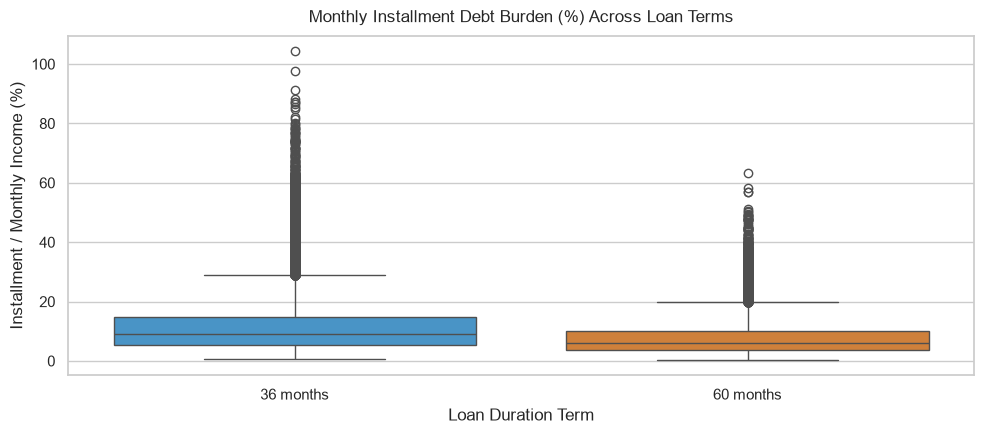

In [10]:
plt.figure(figsize=(10, 4.5))
sns.boxplot(data=df, x='Term', y='InstallmentToIncome', palette=['#3498db', '#e67e22'])
plt.title('Monthly Installment Debt Burden (%) Across Loan Terms', fontsize=12, pad=10)
plt.xlabel('Loan Duration Term')
plt.ylabel('Installment / Monthly Income (%)')
plt.tight_layout()
plt.show()


## 11. Days Past Due (DPD) Profile & Delinquency Incidence
Compute the baseline incidence of non-zero delinquency.


In [11]:
print(f'Current Accounts (0 DPD)      : {(df["DaysPastDue"] == 0).mean()*100:.2f}% ({(df["DaysPastDue"] == 0).sum():,} loans)')
print(f'Delinquent Accounts (>0 DPD)  : {(df["DaysPastDue"] > 0).mean()*100:.2f}% ({(df["DaysPastDue"] > 0).sum():,} loans)')


Current Accounts (0 DPD)      : 84.76% (88,995 loans)
Delinquent Accounts (>0 DPD)  : 15.24% (16,005 loans)


## 12. Delinquency Aging Function Definition (30/60/90+ DPD)
Define standard banking aging classifications.


In [12]:
def map_aging_bucket(dpd):
    if dpd == 0:
        return '0. Current / Performing'
    elif dpd < 30:
        return '1. 1-29 DPD (Grace)'
    elif dpd < 60:
        return '2. 30-59 DPD'
    elif dpd < 90:
        return '3. 60-89 DPD'
    else:
        return '4. 90+ DPD (NPA)'

print('Delinquency aging bucketing function compiled.')


Delinquency aging bucketing function compiled.


## 13. Application of Delinquency Aging Logic
Categorize every loan into regulatory delinquency buckets.


In [13]:
df['AgingBucket'] = df['DaysPastDue'].apply(map_aging_bucket)
ag_tab = df['AgingBucket'].value_counts().sort_index().reset_index()
ag_tab.columns = ['AgingBucket', 'AccountCount']
ag_tab['Share_Pct'] = (ag_tab['AccountCount'] / ag_tab['AccountCount'].sum() * 100).round(2)
ag_tab


,AgingBucket,AccountCount,Share_Pct
0,0. Current / Performing,88995,84.76
1,1. 1-29 DPD (Grace),659,0.63
2,2. 30-59 DPD,655,0.62
3,3. 60-89 DPD,581,0.55
4,4. 90+ DPD (NPA),14110,13.44


## 14. Visual 2: Delinquency Aging Bucket Customer Volumes (Horizontal Bar Chart)
Horizontal bar chart displaying loan volumes per delinquency stage.


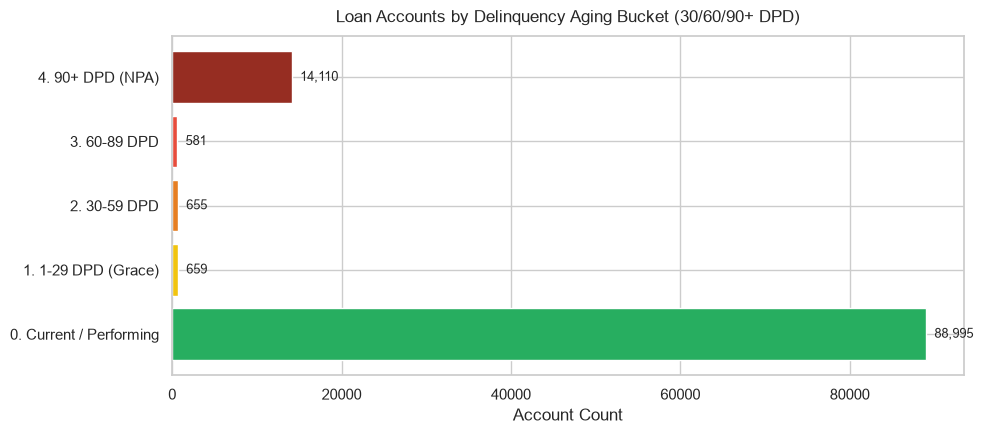

In [14]:
plt.figure(figsize=(10, 4.5))
palette_ag = ['#27ae60', '#f1c40f', '#e67e22', '#e74c3c', '#962d22']
bars = plt.barh(ag_tab['AgingBucket'], ag_tab['AccountCount'], color=palette_ag)
plt.title('Loan Accounts by Delinquency Aging Bucket (30/60/90+ DPD)', fontsize=12, pad=10)
plt.xlabel('Account Count')
for b in bars:
    w = b.get_width()
    plt.text(w + 1000, b.get_y() + b.get_height()/2, f'{w:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()


## 15. Regulatory Non-Performing Asset (NPA) Binary Flag Creation
Tag loans >= 90 DPD as regulatory NPAs.


In [15]:
df['IsNPA'] = (df['DaysPastDue'] >= 90).astype(int)
print(f'Total Regulatory NPAs (90+ DPD): {df["IsNPA"].sum():,} loans ({df["IsNPA"].mean()*100:.2f}% of portfolio)')


Total Regulatory NPAs (90+ DPD): 14,110 loans (13.44% of portfolio)


## 16. Portfolio at Risk (PAR 90) Capital Quantification
Compute total funded capital locked in non-performing assets.


In [16]:
par90_capital = df.loc[df['IsNPA'] == 1, 'LoanAmount'].sum()
total_capital = df['LoanAmount'].sum()
print(f'PAR 90 Capital Exposure: ${par90_capital:,.2f}')
print(f'PAR 90 Ratio           : {par90_capital / total_capital * 100:.2f}% of total funded portfolio.')


PAR 90 Capital Exposure: $222,766,000.00
PAR 90 Ratio           : 13.42% of total funded portfolio.


## 17. Borrower Risk Scorecard Segmentation Implementation
Apply multi-variable underwriting scorecard criteria to classify Low, Moderate, High Risk tiers.


In [17]:
high_risk_cond = (
    (df['Grade'].isin(['D', 'E', 'F', 'G'])) |
    ((df['DTI'] > 21.3) & (df['FicoScore'] < 695)) |
    ((df['Inquiries6M'] >= 2) & (df['RevolvingUtilization'] > 55.0))
)

low_risk_cond = (
    (df['Grade'].isin(['A', 'B'])) &
    (df['DTI'] < 16.0) &
    (df['FicoScore'] >= 720) &
    (df['Inquiries6M'] == 0)
)

df['RiskTier'] = 'Moderate Risk'
df.loc[high_risk_cond, 'RiskTier'] = 'High Risk'
df.loc[low_risk_cond, 'RiskTier'] = 'Low Risk'
print('Risk tiering classification successfully applied.')


Risk tiering classification successfully applied.


## 18. Risk Tier Metrics Table & Loss Concentration
Assess account volumes and write-off losses across tiers.


In [18]:
rt_tab = df.groupby('RiskTier').agg(
    AccountCount=('LoanID', 'count'),
    TotalExposure=('LoanAmount', 'sum'),
    RealizedLoss=('ChargedOffAmount', 'sum')
).reindex(['Low Risk', 'Moderate Risk', 'High Risk']).reset_index()
rt_tab['AccountShare_Pct'] = (rt_tab['AccountCount'] / rt_tab['AccountCount'].sum() * 100).round(2)
rt_tab['LossShare_Pct'] = (rt_tab['RealizedLoss'] / rt_tab['RealizedLoss'].sum() * 100).round(2)
rt_tab


,RiskTier,AccountCount,TotalExposure,RealizedLoss,AccountShare_Pct,LossShare_Pct
0,Low Risk,10923,172344000,3.165771e+06,10.40,2.02
1,Moderate Risk,55504,878183000,5.307390e+07,52.86,33.89
2,High Risk,38573,609560000,1.003867e+08,36.74,64.09


## 19. Visual 3: Borrower Volume Distribution Across Risk Tiers (Bar Chart)
Visualizing portfolio composition by risk tier.


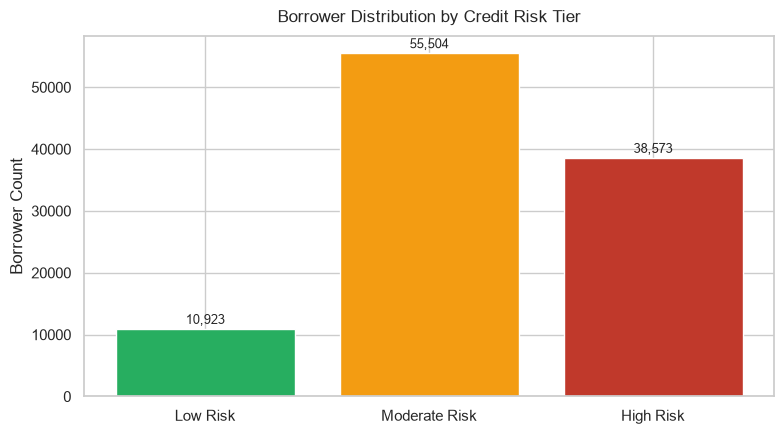

In [19]:
plt.figure(figsize=(8, 4.5))
palette_rt = ['#27ae60', '#f39c12', '#c0392b']
bars = plt.bar(rt_tab['RiskTier'], rt_tab['AccountCount'], color=palette_rt)
plt.title('Borrower Distribution by Credit Risk Tier', fontsize=12, pad=10)
plt.ylabel('Borrower Count')
for b in bars:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2, h + 800, f'{h:,}', ha='center', fontsize=9)
plt.tight_layout()
plt.show()


## 20. Origination Vintage Cohort Verification
Confirm that all 16 quarterly origination cohorts are accurately tagged.


In [20]:
print(f'Distinct Quarterly Vintages Identified: {df["Vintage"].nunique()}')
print('Vintages:', sorted(df['Vintage'].unique()))


Distinct Quarterly Vintages Identified: 16
Vintages: ['2018-Q1', '2018-Q2', '2018-Q3', '2018-Q4', '2019-Q1', '2019-Q2', '2019-Q3', '2019-Q4', '2020-Q1', '2020-Q2', '2020-Q3', '2020-Q4', '2021-Q1', '2021-Q2', '2021-Q3', '2021-Q4']


## 21. Quality Verification & Sanity Constraints
Execute defensive data assertions on values, bounds, and identifiers.


In [21]:
assert (df['LoanAmount'] > 0).all(), 'Validation Failure: Non-positive loan amount.'
assert (df['FicoScore'] >= 580).all(), 'Validation Failure: Out-of-bounds FICO score.'
assert df['LoanID'].nunique() == len(df), 'Validation Failure: Duplicate loan keys.'
print('All post-sanitation assertions PASSED (100% Data Integrity).')


All post-sanitation assertions PASSED (100% Data Integrity).


## 22. Serialization of Sanitized Analytical Fact Dataset
Serialize the cleaned fact table to `data/loan_portfolio_clean.csv`.


In [22]:
OUTPUT_PATH = 'data/loan_portfolio_clean.csv'
df.to_csv(OUTPUT_PATH, index=False)
print(f'Successfully serialized {len(df):,} cleaned records to {OUTPUT_PATH}.')
print(f'Total Attributes: {len(df.columns)} columns.')


Successfully serialized 105,000 cleaned records to data/loan_portfolio_clean.csv.
Total Attributes: 34 columns.
